HOUSE PRICE PREDICTION PROJECT
Dataset loaded successfully!
Dataset shape: (20640, 9)

First five rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge  

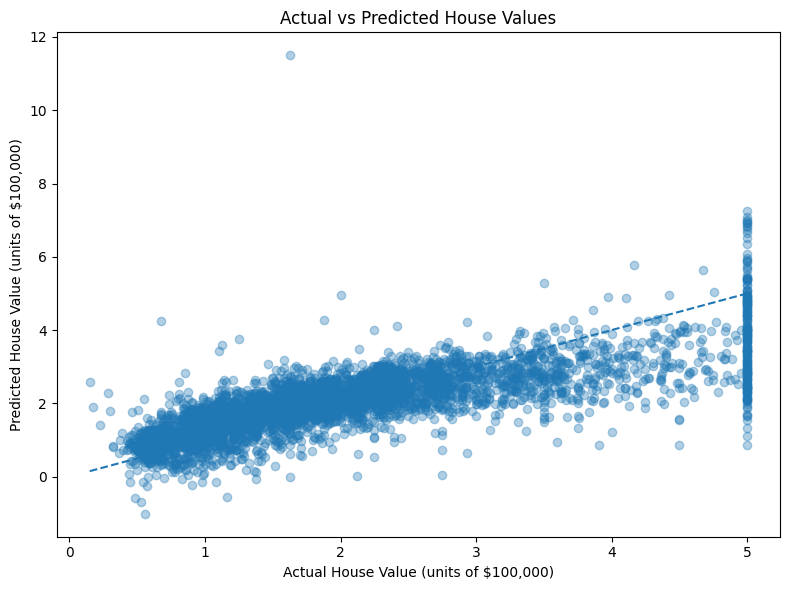

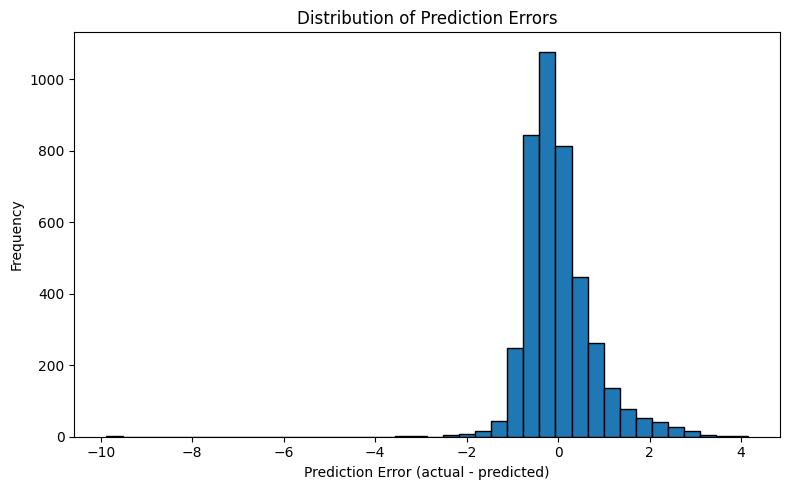

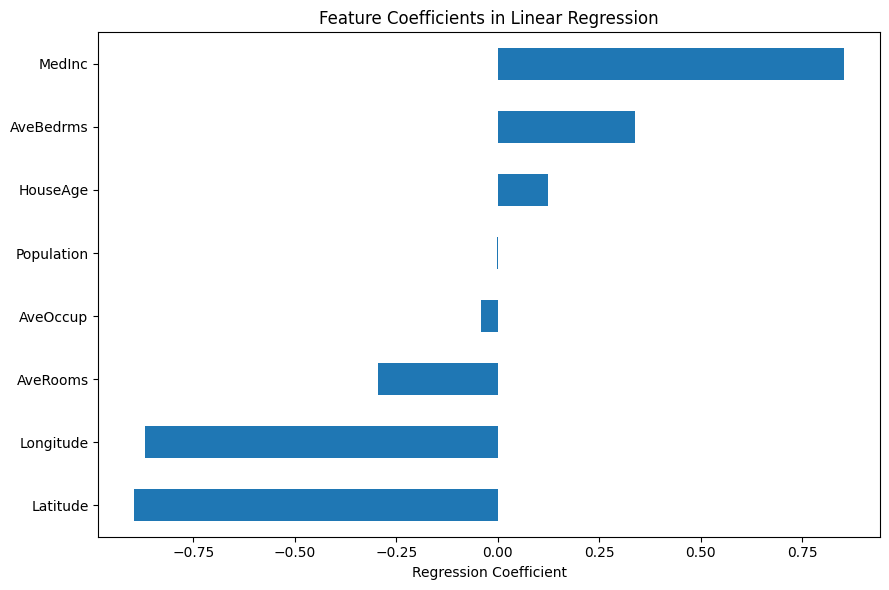


Project completed successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("HOUSE PRICE PREDICTION PROJECT")
print("=" * 40)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R²): {r2:.4f}")

print("\nNote: Target values are measured in units of $100,000.")

results = pd.DataFrame({
    "Actual Price (units of $100,000)": y_test.to_numpy(),
    "Predicted Price (units of $100,000)": y_pred
})

print("\nSample Predictions:")
print(results.head(10).round(3).to_string(index=False))


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.xlabel("Actual House Value (units of $100,000)")
plt.ylabel("Predicted House Value (units of $100,000)")
plt.title("Actual vs Predicted House Values")
plt.tight_layout()
plt.show()


errors = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=40, edgecolor="black")
plt.xlabel("Prediction Error (actual - predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

coefficients = pd.Series(
    model.named_steps["linearregression"].coef_,
    index=X.columns
).sort_values()

plt.figure(figsize=(9, 6))
coefficients.plot(kind="barh")
plt.xlabel("Regression Coefficient")
plt.title("Feature Coefficients in Linear Regression")
plt.tight_layout()
plt.show()

print("\nProject completed successfully!")